# Lecture 9 – Getting data from web pages

QSS 20 · Modern Statistical Computing · Fall 2026

### Agenda

- Read the HTML of a web page as a tree of elements.
- Find elements with Beautiful Soup, and read their text and attributes.
- Turn repeated elements, such as quote cards, into a DataFrame.
- Read HTML tables, including merged cells, by hand and with `pd.read_html`.
- Check a site's access rules before you send a request.

### Setup: install once

This lecture adds two packages: `beautifulsoup4` parses HTML, and `lxml`
lets pandas read HTML tables. Install them once, in a terminal, not in this notebook:

```bash
conda activate qss20
conda install beautifulsoup4 lxml
```

- `conda activate qss20` makes the course environment the active one, so
  `conda install` puts the packages there. Type `y` when conda asks to
  proceed.
- If an import in the next cell still fails, restart the kernel
  (Kernel → Restart Kernel) and run it again.

### Setup: imports and folders

In [1]:
import time
from io import StringIO
from pathlib import Path
from urllib.parse import urljoin

import matplotlib.pyplot as plt
import pandas as pd
import requests
from bs4 import BeautifulSoup
from IPython.display import HTML

pd.set_option('display.max_rows', 8)

# Sharp figures on high-resolution screens, from lecture 6.
%config InlineBackend.figure_format = 'retina'

RAW = Path('../../data/raw')          # pages saved on 8 October 2026
DERIVED = Path('../../data/derived')  # tables built here, for lecture 10
LIVE = Path('../../data/live')        # today's requests: Git ignores this
LIVE.mkdir(exist_ok=True)

- `RAW` holds copies of the web pages that we saved on 8 October. Every
  table today reads these copies, so everyone gets the same output, even if
  a page changes. Anything you download yourself goes to `LIVE`.

## Web pages without an API

- In lecture 8, the city's crash API sent back JSON: records with named
  fields that pandas turned into a table in one step.
- Most web pages have no API. The server sends **HTML** (HyperText Markup
  Language), the text that your browser draws as a page. **Web scraping**
  means writing code that reads this HTML and pulls out the values you need.
- If a site offers an API or a file to download, use that. A site can change
  its page layout at any time, and your scraping code then stops working.

Scrape politely:

- Read the site's terms of use and its `robots.txt` file.
- Send requests slowly, and say who you are in the `User-Agent` header.
- Save each page once, then parse the saved copy as many times as you need.

## What code would look like

In [ ]:
# 1. Send the HTTP request
url = "https://example.com"
response = requests.get(url)

# Check if the page loaded successfully (Status 200)
if response.status_code == 200:
    # 2. Parse the HTML content 
    soup = BeautifulSoup(response.content, "html.parser")
    
    # 3. Find and extract data (e.g., all <h2> headings with class "title")
    headings = soup.find_all("h2", class_="title")
    
    # 4. Loop and print the cleaned text
    for heading in headings:
        print(heading.text.strip())

## First page: Quotes to Scrape

Open **[Quotes to Scrape, page 1](https://quotes.toscrape.com/page/1/)** in
your browser. It is a practice site for learning to scrape.

<img src="images/web-quotes.png" width="760" alt="Page 1 of Quotes to Scrape, with three quote cards visible. The first card: The world as we have created it is a process of our thinking. It cannot be changed without changing our thinking. By Albert Einstein, with an (about) link, and the tags change, deep-thoughts, thinking, and world. The second card: It is our choices, Harry, that show what we truly are, far more than our abilities, by J.K. Rowling, tags abilities and choices. The third card is by Albert Einstein. On the right, a box titled Top Ten tags lists love, inspirational, life, humor, books, reading, friendship, friends, truth, and simile">

- Page 1 has ten quote cards; the screenshot shows the first three. Each card
  has the quote, the author, an "(about)" link to a page on the author, and
  a few tags.
- The "Top Ten tags" box on the right belongs to the page, not to any card.

### Goal: one row per quote card

Build a DataFrame with one row per card. This is the first row:

| quote | author | author_url | tags |
|---|---|---|---|
| “The world as we have created it is a process of our thinking. …” | Albert Einstein | https://quotes.toscrape.com/author/Albert-Einstein | ['change', 'deep-thoughts', 'thinking', 'world'] |

- A quote can have several tags, so the `tags` column holds a list.

### What the server sends

`data/raw/quotes/page-1.html` is a copy of page 1, saved on 8 October. It
holds the same text that `requests.get(url).text` returns for this page.
Reading the file sends no request to the site.

In [2]:
page_1 = (RAW / 'quotes' / 'page-1.html').read_text(encoding='utf-8')
print(len(page_1))
print(page_1[:700])

11021
<!DOCTYPE html>
<html lang="en">
<head>
	<meta charset="UTF-8">
	<title>Quotes to Scrape</title>
    <link rel="stylesheet" href="/static/bootstrap.min.css">
    <link rel="stylesheet" href="/static/main.css">
    
    
</head>
<body>
    <div class="container">
        <div class="row header-box">
            <div class="col-md-8">
                <h1>
                    <a href="/" style="text-decoration: none">Quotes to Scrape</a>
                </h1>
            </div>
            <div class="col-md-4">
                <p>
                
                    <a href="/login">Login</a>
                
                </p>
            </div>
        </div>
    

<div class="row">
    <


- This is raw HTML. The first 700 characters hold the page's title and its
  header bar. The quotes come further down, mixed in with tags
  such as `<div class="quote">` and `<span class="text">`. The browser reads
  these tags to lay out the page.

In [3]:
'Albert Einstein' in page_1

True

- A plain string search finds the name somewhere in 11,000 characters. It
  cannot tell us which quote goes with which author, or which tags go with
  which quote. To get those pairs right, we need the structure of the HTML.

## How HTML is built

Start with a page that is small enough to read at a glance. `toy_html` has a
heading, a paragraph with a link, and a table with two rows of US traffic
deaths. We will return to that table in the second half of class.

In [4]:
toy_html = '''
<html>
  <body>
    <h1>Traffic deaths</h1>
    <p>National counts. <a href="https://en.wikipedia.org">Source</a></p>
    <table class="wikitable">
      <tr><th>Year</th><th>Deaths</th></tr>
      <tr><td>2013</td><td>32,893</td></tr>
      <tr><td>2021</td><td>43,230</td></tr>
    </table>
  </body>
</html>
'''
HTML(toy_html)

Year,Deaths
2013,"32,893"
2021,"43,230"


- `HTML(...)`, from `IPython.display`, draws the text the way a browser does.
  Compare the drawing with the text: every visible piece sits between a pair
  of tags.

### Elements, tags, and attributes

- An **element** is one piece of the page, such as a heading, a paragraph, or
  one table cell. `<h1>Traffic deaths</h1>` is an element.
- **Tags** mark where an element starts and ends: `<h1>` starts the heading,
  and `</h1>` ends it. The tag name says what kind of element it is.
- An **attribute** sits inside a start tag and adds information.
  `href="https://en.wikipedia.org"` stores the link's address.
  `class="wikitable"` puts a label on the table; the site's style rules, and
  our code, can find elements by that label.

| Tag | What it marks |
|---|---|
| `div` | a section that groups other elements |
| `span`, `small` | a short piece of text inside a line |
| `p` | a paragraph |
| `a` | a link; the address is in its `href` attribute |
| `h1`, `h2`, … | headings |
| `table`, `tr`, `th`, `td` | a table, a table row, a header cell, a data cell |

### The page is a tree

<img src="images/html-tree.png" width="900" alt="The small page drawn as a tree. html contains body. body contains three children: h1 with the text Traffic deaths, p with the text National counts and an a link with the text Source, and a table with class wikitable. The table contains three tr rows. The first row holds two th cells, Year and Deaths. The second row holds two td cells, 2013 and 32,893. The third row holds two td cells, 2021 and 43,230.">

- Each element sits inside another one. `<body>` holds the heading, the
  paragraph, and the table. The table holds three rows, and each row holds
  two cells.
- An element inside another is its **child**; the outer element is its
  **parent**. The text, in yellow, sits at the ends of the branches.

### Beautiful Soup builds the tree in Python

[Beautiful Soup](https://www.crummy.com/software/BeautifulSoup/bs4/doc/)
reads HTML text and builds this tree as Python objects. We can then search
the tree by tag name and by attribute.

In [5]:
toy = BeautifulSoup(toy_html, 'html.parser')
type(toy)

bs4.BeautifulSoup

In [6]:
toy


<html>
<body>
<h1>Traffic deaths</h1>
<p>National counts. <a href="https://en.wikipedia.org">Source</a></p>
<table class="wikitable">
<tr><th>Year</th><th>Deaths</th></tr>
<tr><td>2013</td><td>32,893</td></tr>
<tr><td>2021</td><td>43,230</td></tr>
</table>
</body>
</html>

- The first argument is the HTML text. `'html.parser'` picks the parser that
  comes with Python. `toy` holds the whole tree.

### `find` returns the first match

In [7]:
toy.find('h1')

<h1>Traffic deaths</h1>

In [8]:
toy.find('td')

<td>2013</td>

- `find('td')` returns one element: the first `td` in the page, reading from
  top to bottom. That is the cell `2013`.

### `find_all` returns every match

In [9]:
toy.find_all('td')

[<td>2013</td>, <td>32,893</td>, <td>2021</td>, <td>43,230</td>]

- `find_all` returns a list of all four data cells. Use it when the page
  repeats the thing you need, such as cells, rows, or quote cards.

### Text and attributes

`.get_text()` reads what the reader sees between the tags. `.get(...)` reads
the value of an attribute, which the reader does not see.

In [10]:
link = toy.find('a')
print(link.get_text())
print(link.get('href'))

Source
https://en.wikipedia.org


- The link's text is `Source`. Its address is in the `href` attribute, so
  `.get_text()` cannot return it.

In [11]:
toy.find('table', class_='wikitable')

<table class="wikitable">
<tr><th>Year</th><th>Deaths</th></tr>
<tr><td>2013</td><td>32,893</td></tr>
<tr><td>2021</td><td>43,230</td></tr>
</table>

- `class_=` keeps only elements with that class. The underscore is there
  because `class` is a reserved word in Python. On a real page, the class is
  often the only way to tell one `div` from another.

### ❓ Question

```python
[td.get_text() for td in toy.find_all('td')]
```

What is the output? Which information from the table is lost?

<details><summary>Answer</summary>

`['2013', '32,893', '2021', '43,230']`: one flat list of four strings. The
list no longer shows which death count belongs to which year. To keep each
year with its count, loop over the rows (`tr`) first, then over the cells in
each row. We will do this for the deaths table later today.

</details>

## Back to the quotes page

Parse the saved copy of page 1 in the same way. The page title is a quick
check that we opened the intended file.

In [12]:
qsoup = BeautifulSoup(page_1, 'html.parser')
print(qsoup.title.get_text())

Quotes to Scrape


### Find the quote cards

In the browser, right-click the first quote and choose **Inspect**. The
browser shows the page's HTML and highlights the quote's element. Move up the
tree until the highlight covers the whole card, including the author and the
tags. That element is `<div class="quote">`, and all ten cards use the same
tag and class.

In [13]:
cards = qsoup.find_all('div', class_='quote')
len(cards)

10

- Ten cards, as in the browser. The page has other `div` elements, for the
  header and the footer; `class_='quote'` leaves them out.

In [14]:
first = cards[0]
print(first.prettify())

<div class="quote" itemscope="" itemtype="http://schema.org/CreativeWork">
 <span class="text" itemprop="text">
  “The world as we have created it is a process of our thinking. It cannot be changed without changing our thinking.”
 </span>
 <span>
  by
  <small class="author" itemprop="author">
   Albert Einstein
  </small>
  <a href="/author/Albert-Einstein">
   (about)
  </a>
 </span>
 <div class="tags">
  Tags:
  <meta class="keywords" content="change,deep-thoughts,thinking,world" itemprop="keywords"/>
  <a class="tag" href="/tag/change/page/1/">
   change
  </a>
  <a class="tag" href="/tag/deep-thoughts/page/1/">
   deep-thoughts
  </a>
  <a class="tag" href="/tag/thinking/page/1/">
   thinking
  </a>
  <a class="tag" href="/tag/world/page/1/">
   world
  </a>
 </div>
</div>



- `.prettify()` prints the HTML with one element per line, indented by its
  depth in the tree. Read the whole card before you write code that pulls
  values out of it.

### Read the quote and the author

The quote is the text of `<span class="text">`, and the author is the text of
`<small class="author">`. Search inside `first`, not the whole page, so that
both values come from the same card.

In [15]:
print(first.find('span', class_='text').get_text(strip=True))
print(first.find('small', class_='author').get_text(strip=True))

“The world as we have created it is a process of our thinking. It cannot be changed without changing our thinking.”
Albert Einstein


- `strip=True` removes spaces and line breaks at both ends of the text.
- If nothing matches, `find` returns `None`, and `.get_text()` then stops
  with an `AttributeError`. That error usually means a misspelled tag or
  class.

### Read the author's link from an attribute

The "(about)" link sits next to the author's name. Its visible text is
`(about)`; the address is in the `href` attribute.

In [16]:
about = first.find('a')
print(about.get_text(strip=True))
print(about.get('href'))

(about)
/author/Albert-Einstein


- `/author/Albert-Einstein` is a **relative URL**: a path on the same site,
  without the site's address in front. Add `https://quotes.toscrape.com` in
  front to get a link that opens outside the page.

### One quote has several tags

The card has one `<a class="tag">` element for each tag. `find` would return
only the first, so use `find_all` and loop over the list.

In [17]:
tag_elements = first.find_all('a', class_='tag')
for tag in tag_elements:
    print(tag.get_text(strip=True))

change
deep-thoughts
thinking
world


- The first quote has four tags. The quote stays one row; its tags become a
  list inside that row.

In [18]:
tags = [tag.get_text(strip=True) for tag in tag_elements]
tags

['change', 'deep-thoughts', 'thinking', 'world']

- This list comprehension, from lecture 8, builds the same list as the loop.
  Read it from the middle: for each `tag` in `tag_elements`, keep its text.

### CSS selectors: a second way to search

A **CSS selector** is a short pattern for finding elements. Web designers
use the same patterns to style pages.

| Selector | Finds |
|---|---|
| `span.text` | a `span` with class `text` |
| `a.tag` | every `a` with class `tag` |
| `li.next a` | an `a` inside an `li` with class `next` (a space means "inside") |

`.select_one(...)` returns the first match, like `find`. `.select(...)`
returns a list, like `find_all`.

In [19]:
print(first.select_one('span.text').get_text(strip=True))
print([a.get_text(strip=True) for a in first.select('a.tag')])

“The world as we have created it is a process of our thinking. It cannot be changed without changing our thinking.”
['change', 'deep-thoughts', 'thinking', 'world']


- `first.find('span', class_='text')` and `first.select_one('span.text')`
  return the same element. Selectors are shorter when the path has several
  steps, such as `li.next a`.

### ❓ Question

```python
first.select_one('a.tag').get_text(strip=True)
```

What is the output? How does it differ from `first.select('a.tag')`?

<details><summary>Answer</summary>

`'change'`, the first of the card's four tags. `select_one` stops at the
first match; `select` returns all four `a.tag` elements.

</details>

<div class="alert alert-success">

### Activity 1 · One row for the second quote

`cards[1]` is the second card on page 1. Build a dictionary `row` with four
keys:

- `quote` and `author`: text;
- `author_url`: a full address that starts with `https://quotes.toscrape.com`;
- `tags`: a list of the card's tags.

Print `row` and check each value against the second card in your browser.
Why does `.get_text()` not give you the author's address?

</div>

### Write the steps once, as a function

Activity 1 built one row by hand. The function `parse_quote` does the same
steps for any card: it takes one `div.quote` element and returns one
dictionary. It only reads HTML that we already have; it sends no request.

In [20]:
BASE_URL = 'https://quotes.toscrape.com'

def parse_quote(card):
    about_link = card.select_one('span a')
    return {
        'quote': card.select_one('span.text').get_text(strip=True),
        'author': card.select_one('small.author').get_text(strip=True),
        'author_url': urljoin(BASE_URL, about_link.get('href')),
        'tags': [a.get_text(strip=True) for a in card.select('a.tag')],
    }

parse_quote(cards[1])

{'quote': '“It is our choices, Harry, that show what we truly are, far more than our abilities.”',
 'author': 'J.K. Rowling',
 'author_url': 'https://quotes.toscrape.com/author/J-K-Rowling',
 'tags': ['abilities', 'choices']}

- The output should match your dictionary from Activity 1.
- `urljoin(BASE_URL, '/author/J-K-Rowling')` puts the site's address in
  front of the relative path.
- `span a` finds the link inside the `span` that holds the author. The
  pattern `a` alone would also match the tag links.

### Apply the function to all ten cards

One card becomes one dictionary. A list of dictionaries becomes a DataFrame,
with the keys as columns, as in lecture 8.

In [21]:
records = [parse_quote(card) for card in cards]
quotes = pd.DataFrame(records)
print('rows:', len(quotes))
quotes[['author', 'quote', 'tags']].head(3)

rows: 10


,author,quote,tags
0,Albert Einstein,“The world as we have created it is a process ...,"[change, deep-thoughts, thinking, world]"
1,J.K. Rowling,"“It is our choices, Harry, that show what we t...","[abilities, choices]"
2,Albert Einstein,“There are only two ways to live your life. On...,"[inspirational, life, live, miracle, miracles]"


- Ten rows for ten cards. Compare two or three rows, tags included, with the
  browser before you use the table.

### Which author has the most quotes on page 1?

In [22]:
quotes['author'].value_counts().head()

author
Albert Einstein    3
J.K. Rowling       1
Jane Austen        1
Marilyn Monroe     1
André Gide         1
Name: count, dtype: int64

- Albert Einstein appears on three of the ten cards. The count describes
  page 1 only, and the site does not check that its quotes are attributed
  correctly.

### Find the next page

At the bottom of page 1 is a **Next** link. Inspect it: the link sits inside
`<li class="next">`, and its `href` is a relative path.

In [23]:
next_link = qsoup.select_one('li.next a')
print(next_link.get('href'))
print(urljoin(BASE_URL, next_link.get('href')))

/page/2/
https://quotes.toscrape.com/page/2/


- This is the same step as the author link: read `href`, then add the site's
  address. The last page has no Next link, so a loop over pages stops when
  `select_one` returns `None`.

### Optional: collect every page live

The loop below downloads each page, saves it, and follows the Next link. It
does not parse the quotes. Keep downloading and parsing in separate steps: if
the parser has a bug, you fix it and rerun it on the saved pages without
sending the requests again.

Leave `RUN_LIVE = False` in class. Before you set it to `True`, check the
site's terms and `robots.txt`.

In [24]:
RUN_LIVE = False
if RUN_LIVE:
    url, page = urljoin(BASE_URL, '/page/1/'), 1
    headers = {'User-Agent': 'QSS20-class (myname@example.com)'}
    while url is not None:
        res = requests.get(url, headers=headers, timeout=30)
        res.raise_for_status()
        (LIVE / f'quotes-page-{page}.html').write_bytes(res.content)
        link = BeautifulSoup(res.text, 'html.parser').select_one('li.next a')
        url = urljoin(BASE_URL, link.get('href')) if link is not None else None
        page += 1
        time.sleep(1)
    print('pages saved:', page - 1)

- `time.sleep(1)` waits one second between requests. The `User-Agent`
  header names your program and gives a contact; replace the placeholder
  with your own email.

## Back to New York: where lecture 8 left off

- The city's crash API gave New York's traffic deaths by year: 297 in 2013,
  231 in 2018, 297 again in 2021, and 229 in 2025.
- Pedestrian deaths fell after 2013; deaths inside vehicles rose after 2019.

- One city's numbers alone do not tell us much. If traffic deaths rose
  across the country after 2013, a flat count in New York is a better
  record than it looks. If they fell everywhere, New York only kept pace.
  The national counts are on a Wikipedia page.

## Second case: US traffic deaths

> **How did traffic deaths change across the United States after 2013, and
> how does that compare with New York City?**

Open the Wikipedia article [Motor vehicle fatality rate in U.S. by year](https://en.wikipedia.org/wiki/Motor_vehicle_fatality_rate_in_U.S._by_year)
and scroll to its table.

- The table has one row per year, from 1899 to 2025. Its columns are deaths,
  vehicle miles traveled, population, and two death rates.
- The quote cards were `div` elements. This page stores its values in an
  HTML table, so we parse rows and cells instead.

### The table on the page

<img src="images/web-us-deaths-table.png" width="760" alt="The deaths table on the Wikipedia page, with the rows for 2013 and for 2019 to 2025. Columns: Year, Deaths, VMT (vehicle miles traveled, billions), Fatalities per 100 million VMT, Population, Fatalities per 100,000 population, and Change in per capita fatalities from previous year. 2013: 32,893 deaths, 10.40 per 100,000. 2021, with footnote 23: 43,230 deaths with footnote 24, 13.02 per 100,000. Between 2022 and 2023, a gray row in italics spans all columns: For recent years, data may not be as consistent as previous years, due to different methods (estimates) or different sources. 2024: 42,789 deaths, with empty population and rate cells. 2025: about 37,810 deaths, marked estimate">

The saved copy from 8 October. This screenshot hides the rows for 1899 to
2012, except 2013, and draws the table wider than the page does.

- Small numbers in brackets, such as `[24]` after 43,230, link to the
  sources that Wikipedia's editors cite.
- The gray row in italics spans all seven columns. It is a note, not a year.
- The 2025 count reads `~37,810 (estimate)`, and the 2024 and 2025 rows have
  empty cells.
- Code needs a rule for each of these before the cells become numbers.

### Tables in HTML: start with the small page

The small page from the start of class had a table with the same structure:
a `table`, three `tr` rows, a header row of `th` cells, and data rows of `td`
cells. Build a DataFrame from it in four steps: find the rows, find each
row's cells, read each cell's text, then name the columns.

In [25]:
toy


<html>
<body>
<h1>Traffic deaths</h1>
<p>National counts. <a href="https://en.wikipedia.org">Source</a></p>
<table class="wikitable">
<tr><th>Year</th><th>Deaths</th></tr>
<tr><td>2013</td><td>32,893</td></tr>
<tr><td>2021</td><td>43,230</td></tr>
</table>
</body>
</html>

In [26]:
toy_rows = toy.find_all('tr')
len(toy_rows)

3

In [27]:
toy_rows[1].find_all('td')

[<td>2013</td>, <td>32,893</td>]

- Searching inside one row keeps the year with its count: `2013` and
  `32,893` come from the same `tr`.

### Every row of the small table

In [28]:
cells = []
for row in toy_rows:
    cells.append([c.get_text() for c in row.find_all(['th', 'td'])])
cells

[['Year', 'Deaths'], ['2013', '32,893'], ['2021', '43,230']]

- `find_all(['th', 'td'])` matches either tag. The header row has `th`
  cells and the data rows have `td` cells, so one line reads both.
- `cells` is a list of lists: one inner list per row.

In [29]:
pd.DataFrame(cells[1:], columns=cells[0])

,Year,Deaths
0,2013,"32,893"
1,2021,"43,230"


- The first inner list gives the column names; the rest give the rows.
- The Wikipedia table follows the same steps. It adds three problems:
  footnote marks inside cells, a note row that is not a year, and numbers
  stored as text.

### Check access before a live request

Wikimedia, which runs Wikipedia, asks programs to name themselves and give a
contact in the `User-Agent` header. Its
[User-Agent policy](https://foundation.wikimedia.org/wiki/Policy:Wikimedia_Foundation_User-Agent_Policy)
says so. The site's `robots.txt` lists the paths that programs should not
visit. Read the default rules, which apply to every program that the file
does not name.

In [30]:
robots = (RAW / 'wikipedia' / 'robots.txt').read_text(encoding='utf-8')
start = robots.find('User-agent: *')
print(robots[start:start + 202])

User-agent: *
Allow: /w/api.php?action=mobileview&
Allow: /w/load.php?
Allow: /api/rest_v1/?doc
Allow: /w/rest.php/site/v1/sitemap
Disallow: /w/
Disallow: /api/
Disallow: /trap/
Disallow: /wiki/Special:


- `User-agent: *` starts the rules for all other programs. Each `Disallow`
  line names a path to stay away from, such as `/w/` or `/wiki/Special:`.
  Each `Allow` line makes an exception inside a path that is off limits.
- Our article's path, `/wiki/Motor_vehicle_fatality_rate_in_U.S._by_year`,
  is not on the list. `robots.txt` covers only paths. Also read the site's
  terms of use, and keep the number of requests low.

### Optional: download the article live

Leave `RUN_WIKI_LIVE = False` in class. If you run it at home, put your own
email in the `User-Agent`. The cell saves the response before any parsing.

In [31]:
RUN_WIKI_LIVE = False
if RUN_WIKI_LIVE:
    url = ('https://en.wikipedia.org/wiki/'
           'Motor_vehicle_fatality_rate_in_U.S._by_year')
    headers = {'User-Agent': 'QSS20-class (myname@example.com)'}
    res = requests.get(url, headers=headers, timeout=30)
    res.raise_for_status()
    (LIVE / 'us-traffic-deaths.html').write_bytes(res.content)
    print(res.status_code, res.headers.get('Content-Type'))

- `raise_for_status()` stops with an error if the server refuses the
  request. `write_bytes(res.content)` saves the page exactly as the server
  sent it.

### Which table holds the deaths?

We saved the article on 8 October as `data/raw/wikipedia/us-traffic-deaths.html`.
A Wikipedia article can hold several tables, so first list every `table`
element with its class and its number of rows.

In [32]:
path = RAW / 'wikipedia' / 'us-traffic-deaths.html'
html = path.read_text(encoding='utf-8')
soup = BeautifulSoup(html, 'html.parser')
[(t.get('class'), len(t.find_all('tr'))) for t in soup.find_all('table')]

[(['wikitable', 'sortable', 'sticky-header'], 129),
 (['nowraplinks', 'mw-collapsible', 'autocollapse', 'navbox-inner'], 6)]

- The article has two tables. The one with 129 rows has the class
  `wikitable`, which Wikipedia uses for data tables. The one with 6 rows is
  the box of links to related articles at the bottom of the page.

### Read the header row

Select the data table by its class. Its first `tr` is the header row, and
its cells are `th`.

In [33]:
table = soup.select_one('table.wikitable')
[th.get_text(' ', strip=True) for th in table.find('tr').find_all('th')]

['Year',
 'Deaths',
 'VMT– Vehicle miles traveled (billions)',
 'Fatalities per 100 million VMT',
 'Population',
 'Fatalities per 100,000 population',
 'Change in per capita fatalities from previous year']

- Seven columns.
- Some header cells hold several pieces of text, such as a word and a line
  break. `get_text(' ', strip=True)` joins the pieces with a space. Without
  the `' '`, the pieces run together.

### Read one row before reading all of them

Before a loop over 128 rows, read one row and compare it with the page. The
loop below keeps the row whose text starts with `2021`, so it finds the row
by its year, not by its position.

In [34]:
rows = table.find_all('tr')
for r in rows:
    if r.get_text().strip().startswith('2021'):
        row_2021 = r
[c.get_text(strip=True) for c in row_2021.find_all(['th', 'td'])]

['2021[23]',
 '43,230[24]',
 '3,230[25]',
 '1.38',
 '332,915,073[26]',
 '13.02',
 '11.6%']

- `43,230[24]`: the cell's text includes its footnote mark. On the page,
  `[24]` is a small raised link to a source, stored in a `sup` element inside
  the cell. The year cell has one too: `2021[23]`.

### ❓ Question

```python
int('43,230[24]'.replace(',', ''))
```

What does this line return?

<details><summary>Answer</summary>

**An error:** `ValueError: invalid literal for int()`. Removing the comma
leaves `'43230[24]'`, which is not a number. Remove the footnote marks from
the tree before you read the text.

</details>

### Remove the footnote marks

Each footnote mark is a `<sup class="reference">` element. Delete all of them
from the table, then read the 2021 row again.

In [35]:
for sup in table.select('sup.reference'):
    sup.decompose()

[c.get_text(strip=True) for c in row_2021.find_all(['th', 'td'])]

['2021', '43,230', '3,230', '1.38', '332,915,073', '13.02', '11.6%']

- `.decompose()` deletes an element and everything inside it from the tree.
  `table.select('sup.reference')` finds every footnote mark in the table.

### Parse every row

Apply the steps from the small table to every row after the header. One row
is a note that spans the whole table, so it has one cell instead of seven.
The loop keeps rows with seven cells and sets the others aside, so we can
print them and read them.

In [36]:
columns = ['year', 'deaths', 'vmt', 'per_vmt', 'population',
           'per_100k', 'change']
records, skipped = [], []
for row in rows[1:]:
    cells = [c.get_text(' ', strip=True) for c in row.find_all(['th', 'td'])]
    if len(cells) != len(columns):
        skipped.append(cells)
        continue
    records.append(dict(zip(columns, cells)))

us = pd.DataFrame(records)
len(us), skipped

(127,
 [['For recent years, data may not be as consistent as previous years, due to different methods (estimates) or different sources']])

- `zip(columns, cells)` pairs each column name with the cell in the same
  position; `dict(...)` turns the pairs into one row.
- The skipped row is the note. It says that recent years may come from
  different methods or sources. Keep that in mind when you compare years.

### Turn the text into numbers

Every cell is still text. Three recent years show what a conversion rule has
to handle.

In [37]:
us.loc[us['year'].isin(['2022', '2024', '2025']),
       ['year', 'deaths', 'per_vmt', 'population']]

,year,deaths,per_vmt,population
123,2022,"42,514",1.35 (estimate) 1.33 (division),"338,289,857"
125,2024,"42,789",1.30,
126,2025,"~37,810 (estimate)",1.14,


- `~37,810 (estimate)` for the 2025 deaths, `1.35 (estimate) 1.33 (division)`
  for the 2022 rate, and empty population cells for 2024 and 2025. A person
  can read these; code needs a rule for each one.

### The conversion rule

Keep the first word of each cell, and remove commas and `~`. Anything that is
still not a number becomes `NaN`. A separate column records which death
counts are estimates, so the table keeps that information.

In [38]:
def to_number(s):
    """Keep the first word, drop commas and '~'; text left over becomes NaN."""
    first = s.str.split(' ').str[0]
    return pd.to_numeric(first.str.replace(',', '').str.replace('~', ''),
                         errors='coerce')

us = us.assign(estimate=us['deaths'].str.contains('estimate'),
               year=us['year'].astype(int),
               deaths=to_number(us['deaths']),
               population=to_number(us['population']),
               per_100k=to_number(us['per_100k']))
us[['year', 'deaths', 'population', 'per_100k', 'estimate']].tail(4)

,year,deaths,population,per_100k,estimate
123,2022,42514,338289857.0,12.76,False
124,2023,40990,339996563.0,12.06,False
125,2024,42789,NaN,NaN,False
126,2025,37810,NaN,NaN,True


- `errors='coerce'` turns an empty cell into `NaN` instead of stopping with
  an error.

### Check the table against itself

Two checks before we use the table. Each year should appear once, with a
death count. The page's rate per 100,000 residents should equal
deaths ÷ population × 100,000.

In [39]:
(len(us), us['year'].is_unique, us['year'].min(), us['year'].max(),
 us['deaths'].isna().sum())

(127, True, 1899, 2025, 0)

In [40]:
own_rate = us['deaths'] / us['population'] * 100_000
gap = (own_rate - us['per_100k']).abs()
us.loc[gap > 0.05, ['year', 'deaths', 'population', 'per_100k']].assign(
    own_rate=own_rate.round(2))

,year,deaths,population,per_100k,own_rate
117,2016,37806,323121000.0,11.59,11.70
118,2017,37473,326213213.0,11.40,11.49
119,2018,36835,327096265.0,11.18,11.26
120,2019,36355,328231337.0,10.99,11.08
123,2022,42514,338289857.0,12.76,12.57


- 127 years, 1899 to 2025, each once, with no missing death count.
- In 5 years, the page's rate differs from our rate by up to 0.19, and the
  page does not say why. When you compare rates, compute them yourself from
  the counts.

### US traffic deaths, 2000 to 2025

Plot deaths by year since 2000. Hollow circles mark the years whose count is
an estimate.

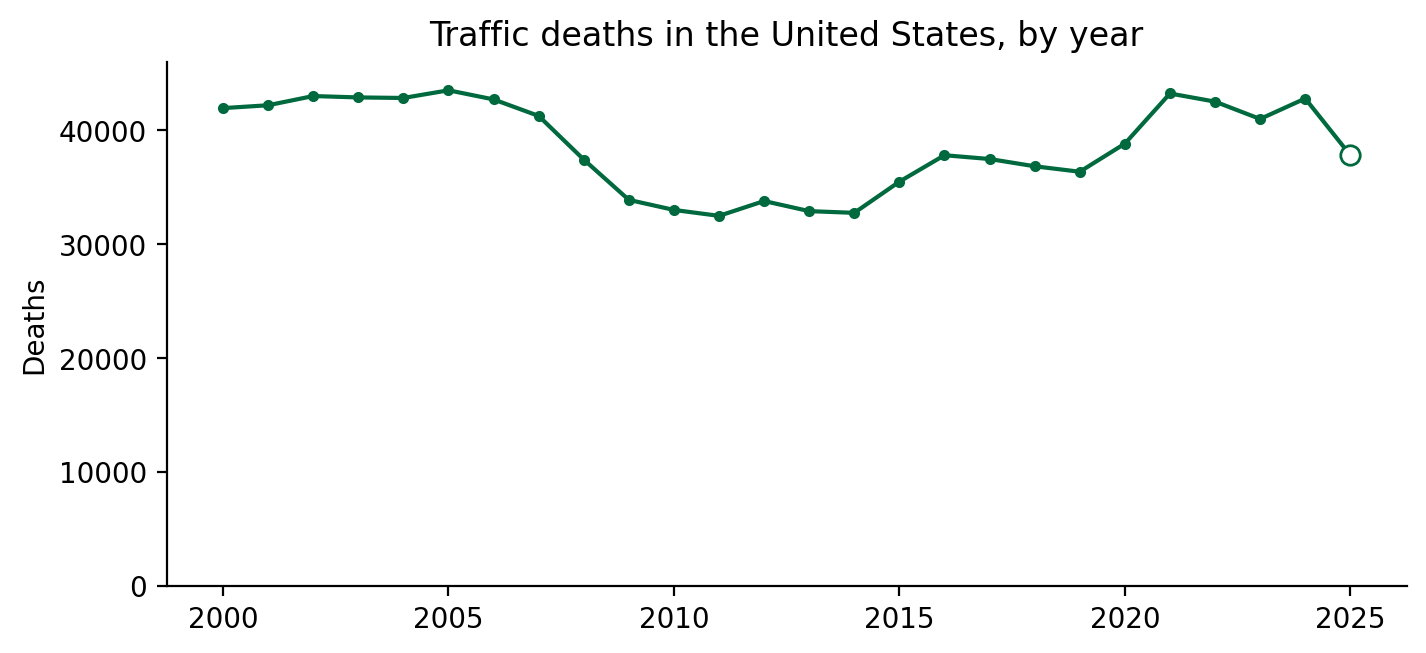

In [41]:
recent = us.loc[us['year'] >= 2000]

fig, ax = plt.subplots(figsize=(8, 3.4))
ax.plot(recent['year'], recent['deaths'], marker='o', ms=3, color='#00693e')
est = recent.loc[recent['estimate']]
ax.plot(est['year'], est['deaths'], 'o', ms=7, mfc='white', color='#00693e')
ax.set(ylim=(0, 46000), ylabel='Deaths',
       title='Traffic deaths in the United States, by year')
ax.spines[['top', 'right']].set_visible(False);

- 32,893 deaths in 2013 and 43,230 in 2021: **31 percent more**. Per 100,000
  residents, the page's rate went from 10.40 to 13.02.
- 40,990 in 2023 and 42,789 in 2024. The 2025 count, drawn hollow, is an
  estimate.
- New York City had 297 deaths in both 2013 and 2021. Over the same years,
  deaths in the whole country rose by about a third.

## New York's population: merged cells with `colspan`

Counts are not rates. A rate for New York needs its population. The
Wikipedia article [Boroughs of New York City](https://en.wikipedia.org/wiki/Boroughs_of_New_York_City)
has a table with each borough's population in the 2020 Census. Open it and
find the table titled "New York City's five boroughs".

<img src="images/web-nyc-boroughs-table.png" width="640" alt="The Wikipedia table New York City's five boroughs. Header rows group the columns into Jurisdiction (Borough, County), Population (Census 2020), Land area (square miles, square km), Density of population (people per square mile, people per square km), and GDP (billions of US dollars, 2024). Five borough rows: The Bronx, Bronx, 1,472,654; Brooklyn, Kings, 2,736,074; Manhattan, New York, 1,694,251; Queens, Queens, 2,405,464; Staten Island, Richmond, 495,747. In the next two rows, City of New York (8,804,190) and State of New York (20,201,249), the name fills both the Borough and the County columns. A last row lists the sources">

Below the five boroughs, the table has two total rows: City of New York and
State of New York. In those rows, one cell covers both the Borough and the
County columns. HTML marks this with the attribute `colspan="2"`:

```html
<tr><td>The Bronx</td><td>Bronx</td><td>1,472,654</td> …
<tr><td colspan="2">City of New York</td><td>8,804,190</td> …
```

### Count the cells in each row

We saved the article on 8 October as `data/raw/wikipedia/nyc-boroughs.html`.
Read it, select the `wikitable`, and print each row's number of cells with
the start of its first three cells.

In [42]:
boroughs_path = RAW / 'wikipedia' / 'nyc-boroughs.html'
boroughs_html = boroughs_path.read_text(encoding='utf-8')
boroughs_soup = BeautifulSoup(boroughs_html, 'html.parser')
boroughs_table = boroughs_soup.select_one('table.wikitable')
for row in boroughs_table.find_all('tr'):
    cells = row.find_all(['th', 'td'])
    print(len(cells), [c.get_text(' ', strip=True)[:16] for c in cells[:3]])

1 ["New York City's "]
5 ['Jurisdiction', 'Population', 'Land area']
8 ['Borough', 'County', 'Census (2020)']
8 ['The Bronx', 'Bronx', '1,472,654']
8 ['Brooklyn', 'Kings', '2,736,074']
8 ['Manhattan', 'New York', '1,694,251']
8 ['Queens', 'Queens', '2,405,464']
8 ['Staten Island', 'Richmond', '495,747']
7 ['City of New York', '8,804,190', '300.5']
7 ['State of New Yor', '20,201,249', '47,123.6']
1 ['Sources : [ 4 ] ']


- A title row with 1 cell, two header rows, five borough rows with 8 cells,
  two total rows with **7** cells, and a row that lists the sources.

### ❓ Question

```python
for row in boroughs_table.find_all('tr'):
    if row.get_text().strip().startswith('City of New York'):
        city = row
cells = city.find_all('td')
(cells[0].get_text(strip=True), cells[0].get('colspan'),
 cells[2].get_text(strip=True))
```

In the borough rows, `cells[2]` is the population. What does `cells[2]` hold
in the "City of New York" row?

<details><summary>Answer</summary>

**`'300.5'`, the land area in square miles.** The first cell spans two
columns (`colspan='2'`), so the row has one cell fewer, and every value after
it sits one position to the left. Code that reads cells by position would
report the city's population as 300.5, with no error.

</details>

### The merged cell moves every value one place left

In [43]:
for row in boroughs_table.find_all('tr'):
    if row.get_text().strip().startswith('City of New York'):
        city = row
cells = city.find_all('td')
(cells[0].get_text(strip=True), cells[0].get('colspan'),
 cells[2].get_text(strip=True))

('City of New York', '2', '300.5')

- Count the cells in each row before you read a value by its position.

<div class="alert alert-success">

### Activity 2 · New York's population

Build a DataFrame `boroughs` from `boroughs_table` with one row per borough
and three columns: `borough`, `county`, and `population` (an integer).

1. How many rows must `boroughs` have, and which rows of the table must you
   leave out?
2. Add up the five populations. Does the sum equal the "City of New York"
   row?

</div>

### Solution: keep the rows with eight cells

The borough rows are the only rows with eight `td` cells. Keep those rows,
then compare their sum with the city's row.

In [44]:
records = []
for row in boroughs_table.find_all('tr'):
    cells = [c.get_text(' ', strip=True) for c in row.find_all('td')]
    if len(cells) == 8:   # borough rows only; total rows have 7 cells
        records.append({'borough': cells[0], 'county': cells[1],
                        'population': int(cells[2].replace(',', ''))})
boroughs = pd.DataFrame(records)
boroughs

,borough,county,population
0,The Bronx,Bronx,1472654
1,Brooklyn,Kings,2736074
2,Manhattan,New York,1694251
3,Queens,Queens,2405464
4,Staten Island,Richmond,495747


In [45]:
city_cells = city.find_all('td')
city_total = int(city_cells[1].get_text(strip=True).replace(',', ''))
boroughs['population'].sum(), city_total

(8804190, 8804190)

- `boroughs` has five rows. If the two total rows stayed in, the city's
  residents would be counted twice, and three times with the state row.
- The five boroughs add up to 8,804,190, the value in the city's row. When a
  page prints a total, compare it with your own sum.

### Merged cells down a column: `rowspan`

`rowspan` is the vertical version of `colspan`: one cell covers several rows.
Tables that list several years for each place often write the place once and
merge it down the column. None of today's saved pages does this, so we write
a small table by hand.

Its numbers come from the New York crash records of lecture 8. Each one is
the number of crashes in which at least one person died, in the Bronx or
Brooklyn, in 2013 or 2014.

In [46]:
spans = '''
<table>
  <tr><th>Borough</th><th>Year</th><th>Fatal crashes</th></tr>
  <tr><td rowspan="2">BRONX</td><td>2013</td><td>32</td></tr>
  <tr><td>2014</td><td>19</td></tr>
  <tr><td rowspan="2">BROOKLYN</td><td>2013</td><td>63</td></tr>
  <tr><td>2014</td><td>66</td></tr>
</table>
'''
HTML(spans)

In [47]:
span_rows = BeautifulSoup(spans, 'html.parser').find_all('tr')[1:]
for r in span_rows:
    print([c.get_text() for c in r.find_all('td')])

['BRONX', '2013', '32']
['2014', '19']
['BROOKLYN', '2013', '63']
['2014', '66']


- The 2014 rows have **two** cells. The browser draws the borough next to
  them, but the HTML holds it only once. Read by position, the year would
  land in the borough column.

### Carry the borough down to the rows below

The loop remembers the last borough it read. A row with three cells starts a
new borough. A row with two cells gets the borough from the row above.

In [48]:
records, borough = [], None
for r in span_rows:
    cells = [c.get_text() for c in r.find_all('td')]
    if len(cells) == 3:          # a row that starts a new borough
        borough, cells = cells[0], cells[1:]
    records.append({'borough': borough, 'year': int(cells[0]),
                    'fatal_crashes': int(cells[1])})
pd.DataFrame(records)

,borough,year,fatal_crashes
0,BRONX,2013,32
1,BRONX,2014,19
2,BROOKLYN,2013,63
3,BROOKLYN,2014,66


- Check the result against the table: four rows, each with a borough, and
  the same counts.

<div class="alert alert-info">

**Key idea.** Count the cells in every row before you read values by
position. A merged cell moves values without an error, and a total row kept
as data counts the same people twice.

</div>

## A shortcut: `pd.read_html`

Each table today took the same steps: find the `table`, loop over its `tr`
rows, read the text of each `th` and `td` cell, and name the columns.
[`pd.read_html`](https://pandas.pydata.org/docs/reference/api/pandas.read_html.html)
does all of these steps in one call. It returns a list with one DataFrame for
each `<table>` element in the HTML.

- Use it when the values you need sit in an HTML table.
- It cannot read the quote cards, because they are `div` elements, not a
  table.

In [49]:
tables = pd.read_html(StringIO(boroughs_html))
len(tables)

3

- Three tables: the borough table and two boxes of links to related
  articles.
- `read_html` expects a file, a path, or a URL. `StringIO(boroughs_html)`
  wraps the text we already have so that it behaves like an open file.
  pandas warns if you pass the HTML text directly.

### What `read_html` does with merged cells

In [50]:
tables[0].iloc[:, :3]

New York City's five boroughsvte  \
                                        Jurisdiction   
                                             Borough   
0                                          The Bronx   
1                                           Brooklyn   
2                                          Manhattan   
3                                             Queens   
4                                      Staten Island   
5                                   City of New York   
6                                  State of New York   
7  Sources:[4][5][6][7] and see individual boroug...   

                                                      \
                                                       
                                              County   
0                                              Bronx   
1                                              Kings   
2                                           New York   
3                                             Queens   
4                                           Richmond   
5                                   City of New York   
6                                  State of New York   
7  Sources:[4][5][6][7] and see individual boroug...   

                                                      
                                          Population  
                                      Census  (2020)  
0                                            1472654  
1                                            2736074  
2                                            1694251  
3                                            2405464  
4                                             495747  
5                                            8804190  
6                                           20201249  
7  Sources:[4][5][6][7] and see individual boroug...

- The boroughs, counties, and populations are right, and pandas already
  turned the populations into numbers.
- Three results need a fix. pandas copied "City of New York" into the County
  column to fill the merged cell. It kept the sources row as data. Its column
  names stack three header rows. Our five-row `boroughs` table has none of
  these problems.

In [51]:
pd.read_html(StringIO(spans))[0]

,Borough,Year,Fatal crashes
0,BRONX,2013,32
1,BRONX,2014,19
2,BROOKLYN,2013,63
3,BROOKLYN,2014,66


- For `rowspan`, it copies the borough down the column, as our loop did.

### What `read_html` does with footnotes and notes

`match=` keeps only the tables whose text contains a given string. It helps
when a page holds many tables.

In [52]:
us_quick = pd.read_html(StringIO(html), match='Vehicle miles')[0]
us_quick.iloc[-6:, :3]

,Year,Deaths,VMT– Vehicle miles traveled (billions)
122,2021[23],"43,230[24]","3,230[25]"
123,2022[10],"42,514[24]",3196
124,"For recent years, data may not be as consisten...","For recent years, data may not be as consisten...","For recent years, data may not be as consisten..."
125,2023,"40,990[27]","3,263[28]"
126,2024,"42,789[30]",NaN
127,2025,"~37,810 (estimate)[31]",NaN


- The footnote marks stay in the text, as in `2021[23]`. `html` is the text
  of the saved page; our `.decompose()` changed the tree in `soup`, not this
  text.
- The note row's text is copied into all seven columns.
- `read_html` saves you the loop over rows and cells. You still remove
  footnotes, drop rows that are not data, and turn text into numbers.

| The values sit in | Use |
|---|---|
| other elements: quote cards, lists, links | Beautiful Soup |
| a `<table>`, and you need control over each cell | Beautiful Soup |
| a `<table>` | `pd.read_html`, then check the header, row count, totals, and footnotes |

### Save the two tables for lecture 10

In [53]:
us[['year', 'deaths', 'population', 'per_100k', 'estimate']].to_csv(
    DERIVED / 'us_traffic_deaths.csv', index=False)
boroughs.to_csv(DERIVED / 'nyc_boroughs.csv', index=False)

- Lecture 10 stores these two tables and the crash records from lecture 8 in
  one database.

## What we found

- Traffic deaths in the United States rose from **32,893** in 2013 to
  **43,230** in 2021, 31 percent more, and stayed above 40,000 through 2024.
- In New York City, deaths in 2021 equaled deaths in 2013: 297.

- What the comparison cannot show:
  - The national numbers come from a page that compiles other sources, and a
    note in the table warns that recent years may not be consistent. Check
    the cited source before you cite a number.
  - The city and the nation differ in many ways, such as how much people
    drive. Different trends do not show that New York's 2014 traffic-safety
    program caused the difference.
  - Counts are not rates. Lecture 10 divides by population, year by year.

## Activity notebook: is the United States an outlier among rich countries?

- **New question:** a table on Wikipedia compares road deaths in 2013 across
  26 countries. Where does the United States rank in that table?
- **New row unit:** one country.
- **What stays the same:** choose a table by what it is, remove footnotes,
  turn text into numbers, and check the result against the page.
- **What changes:** the page holds several tables, and each country's name sits
  in a `th` cell.
- Open [Vision Zero](https://en.wikipedia.org/wiki/Vision_Zero) and find the
  "Road fatalities in 2013" table. Then open `lec09_activity.ipynb`.

## Summary

| Goal | Write |
|---|---|
| Show HTML as a browser would | `HTML(html_text)` |
| Parse HTML | `soup = BeautifulSoup(html, 'html.parser')` |
| First match, or every match | `soup.find('td')`, `soup.find_all('td')` |
| Match by class | `soup.find_all('div', class_='quote')` |
| Match with a CSS selector | `soup.select_one('table.wikitable')`, `card.select('a.tag')` |
| Text inside an element | `el.get_text(' ', strip=True)` |
| An attribute's value | `el.get('href')` |
| Full address from a relative link | `urljoin(base_url, el.get('href'))` |
| See the HTML of one element | `print(el.prettify())` |
| Every cell of a row | `row.find_all(['th', 'td'])` |
| Delete elements, such as footnotes | `for s in table.select('sup.reference'): s.decompose()` |
| Pair names with values | `dict(zip(columns, cells))` |
| Text to numbers, blanks to `NaN` | `pd.to_numeric(s, errors='coerce')` |
| Name your program | `requests.get(url, headers={'User-Agent': '...'})` |
| Save a page as sent | `path.write_bytes(res.content)` |
| Every table, quickly | `pd.read_html(StringIO(html), match='...')` |